# Bosonic state preparation with a Rabi-driven qubit: optimize, ship, simulate

End-to-end pipeline for the two-tone sideband preparation of the thesis *Bosonic state initialization with hardware closed-loop optimization using a Rabi-driven qubit*. The setup is a 3D-cavity memory dispersively coupled to a transmon, with a Rabi drive $\Omega_R/2\pi = 6$ MHz and two sideband tones at $\omega_c \pm \Omega_R$.

1. **Effective-Hamiltonian optimizer.** The two sideband phases $\phi_1(t), \phi_2(t)$ are Fourier series, optimized in the displaced, dressed frame ($g_{\rm eff} = \alpha\chi/2$) with the smoothness term, the phase-derivative hinge and a 2 µs window. Targets: Fock, cat and GKP. Objectives: full fidelity, or the measurable characteristic-function losses.
2. **Ship to hardware.** Rescale along the $\alpha T$ invariant, build the beat-aligned schedule on the 4 ns grid, and write the solution folder in the format the QUA side reads.
3. **Displaced-frame simulation of the full sequence.** Time-dependent and constant Stark compensation side by side, and an integer-time search over beat-aligned segment lengths.
4. **Reproduction check** against the shipped folder.

The code is in [`rabi_sideband_pipeline.py`](rabi_sideband_pipeline.py). It consolidates the thesis project's simulation notebooks and scripts.

**Default run:** the even cat with $\alpha_{\rm cat} = 1.5$ at $\alpha_{\rm opt} = 17$. It reproduces the shipped `cat15_Rabi6_chi18_full_a17_T5000` and takes about 2 minutes on a laptop CPU. Set `TARGET = 'fock2'` or `'gkp'` in §0 for the other presets. New folders go to `output/rabi_sideband_pipeline/`, which git ignores.

*Requirements:* NumPy, SciPy, TensorFlow ≥ 2.16, QuTiP 5, Matplotlib. Run from this folder. §1–3 need nothing else. The hardware-format check in §2 needs the lab's QUA-side generators (`make_two_sideband_amp_oc.py`, `make_rabi_oc_amp.py`, `oc_cell_from_params.py`), and §4 and the comparison lines need the shipped solution folders; neither is in this repository, so those cells print a skip message. The outputs saved here come from a run with both present.

## 0. Setup

In [1]:
import os, time
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rabi_sideband_pipeline as rp

rp.use_cpu_only()                     # before any TensorFlow work: the sector propagation is CPU-bound
os.chdir(rp.ROOT)                     # the shipped folders live at the repository root
OUT = Path('output/rabi_sideband_pipeline'); OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 64, 'font.size': 9})

D = rp.DEVICE
print('chi/2pi = %.1f kHz (design value of every shipped file; cavity Ramsey: %.2f kHz)'
      % (D['chi_Hz']/1e3, D['chi_measured_Hz']/1e3))
print('f_Rabi = %.0f MHz -> beat-null spacing h = %.2f ns; T1q = %.1f us, T1c = %.0f us'
      % (D['f_rabi_Hz']/1e6, rp.beat_ns(), D['T1q']*1e6, D['T1c']*1e6))
print('k beats on the 4 ns grid:', {k: rp.beat_aligned(k) for k in range(1, 7)})

chi/2pi = 18.2 kHz (design value of every shipped file; cavity Ramsey: -16.09 kHz)
f_Rabi = 6 MHz -> beat-null spacing h = 83.33 ns; T1q = 22.3 us, T1c = 150 us
k beats on the 4 ns grid: {1: 84, 2: 168, 3: 248, 4: 332, 5: 416, 6: 500}


**Presets.** Each preset reproduces the optimization protocol of a shipped folder. The cat and GKP presets use the characteristic-function objective; Fock $|2\rangle$ uses the full fidelity. `source` is the effective-model solution, and `shipped` is the measurement-ready folder made from it.

In [2]:
PRESETS = {
    # even cat alpha_cat = 1.5: char-func objective, 300 iterations + 300 warm-start iterations
    'cat':   dict(target=dict(kind='cat', alpha_cat=1.5), alpha_opt=17, objective='charfunc',
                  n_steps=500, iters=300, warm_iters=300, T_oc_ns=5000, sched=(332, 84, 168, 0, 332),
                  Nc_sim=40, source='cat15_charfunc_a17', source_batch=0,
                  shipped='cat15_Rabi6_chi18_full_a17_T5000', tag='cat15'),
    # Fock |2>: full-fidelity objective
    'fock2': dict(target=dict(kind='fock', n=2), alpha_opt=20, objective='fidelity',
                  n_steps=500, iters=300, warm_iters=0, T_oc_ns=6000, sched=(416, 84, 168, 0, 500),
                  Nc_sim=40, source='fock2', source_batch=0,
                  shipped='fock2_Rabi6_chi18_full_6000', tag='fock2'),
    # GKP |0_L>, Delta = 0.340: -log(p_g F_est) at the 32 plan points, 1200 iterations
    'gkp':   dict(target=dict(kind='gkp', Delta=0.3401187062263489), alpha_opt=37, objective='charfunc',
                  n_steps=250, iters=1200, warm_iters=0, T_oc_ns=6500, sched=(416, 84, 84, 0, 332),
                  Nc_sim=50, source='gkp_deltaopt_a37', source_batch=0,
                  shipped='gkp_Rabi6_chi18_full_a37_T6500', tag='gkp'),
}
TARGET = 'cat'

P = PRESETS[TARGET]
target = rp.make_target(N=50, **P['target'])
have_shipped = os.path.isdir(P['source']) and os.path.isdir(P['shipped'])
plan = rp.load_gkp_plan(P['shipped'] if have_shipped else None) if target['kind'] == 'gkp' else None
print('%s | parity %s | alpha_opt %g | objective %s | shipped folders present: %s'
      % (target['name'], target['parity'], P['alpha_opt'], P['objective'], have_shipped))

even cat alpha=1.5 | parity even | alpha_opt 17 | objective charfunc | shipped folders present: True


## 1. Effective-Hamiltonian optimizer

Displacing by the classical field $\beta(t)$, moving into the Rabi frame and keeping the resonant terms gives (thesis Ch. 5)

$$\frac{H_{\rm eff}}{\hbar}=-g_{\rm eff}\left(e^{i\phi_1}\sigma_+a^\dagger+e^{i\phi_2}\sigma_-a^\dagger+{\rm h.c.}\right),\qquad g_{\rm eff}=\frac{\alpha\chi}{2},$$

with $\sigma_\pm$ acting between the dressed states ($|g\rangle \equiv |-\rangle$). Each phase has $N_h = 20$ harmonics of the window $T = 2$ µs,
$\phi_j(t)=\sum_k C_{jk}(\cos\omega_k t-1)+S_{jk}\sin\omega_k t$. Thus $\phi_j(0)=\phi_j(T)=0$, and the window joins the beat-aligned ramps.

**Objectives** (per batch member; a batch is a set of independent random starts):
- `'fidelity'`: $-\log F_{\rm joint}$, where $F_{\rm joint}=|\langle \psi_{\rm t}\otimes q|\psi(T)\rangle|^2$.
- `'charfunc'` (measurable quantities only):
  - Fock: $100\,\langle|C-C_{\rm t}|^2\rangle$ on 4 cuts × 25 radii ($|\beta|\le3$), plus $50(1-p)^2$ and $50\times$ an isotropy penalty.
  - Cat: the same on 4 cuts × 41 signed radii ($|\beta|\le4$), weighted by $1+4e^{-(|\beta|-2\alpha_{\rm cat})^2/0.5}$, without the isotropy term.
  - GKP: $-\log(p_g F_{\rm est})$ with the 32-point linear estimator $F_{\rm est}=a_0+\sum_j a_j\,{\rm Re}\,C_g(\beta_j)$.

**Hardware constraints (regularization):** $\mathcal R = 10^{-4}\langle k(C^2+S^2)\rangle + \frac{15}{\dot\phi_{\max}^2}\langle{\rm ReLU}(|\dot\phi|-\dot\phi_{\max})^2\rangle$, with $\dot\phi_{\max}=2\pi\times5$ MHz at $T=2$ µs. This bound becomes 0.9–2 MHz once the solution is stretched to the hardware window, well below $\Omega_R$.

**Propagation.** Starting from $|0,g\rangle$, the state stays in the sector $\{|n,\,n \bmod 2\rangle\}$. There $H(\phi_1,\phi_2)=V\,H(0,0)\,V^\dagger$ with $V$ diagonal, so each piecewise-constant step is $V U_0 V^\dagger$ with a single precomputed $U_0$. This is exact, and fast enough for a CPU (thesis App. A.1).

In [3]:
print('sector reduction vs the full qubit-cavity propagator: max error %.1e' % rp.check_sector_reduction())
t0 = time.time()
kw = dict(objective=P['objective'], T=2e-6, n_steps=P['n_steps'], batch=3, seed=42, plan=plan)
opt = rp.EffHOptimizer(target, P['alpha_opt'], **kw)
opt.optimize(P['iters'], every=100)
hist = dict(opt.hist)
if P['warm_iters']:
    # warm restart with a fresh Adam, as for the shipped cat: the best member and two perturbed copies
    rng = np.random.default_rng(7)
    ws = {k: np.stack([v, v + rng.normal(0, .02, v.shape), v + rng.normal(0, .05, v.shape)])
          for k, v in opt.best['coeffs'].items()}
    opt = rp.EffHOptimizer(target, P['alpha_opt'], warm_start=ws, **kw)
    opt.optimize(P['warm_iters'], every=100)
    hist = {k: hist[k] + opt.hist[k] for k in hist}
sol = opt.solution(); sol['history'] = hist
print('\n%d iterations in %.0f s: F_joint = %.5f, p_herald = %.5f, F_cav = %.5f, max |phidot|/2pi = %.2f MHz'
      % (len(hist['loss']), time.time() - t0, sol['F_joint'], sol['p_herald'], sol['F_cav'], sol['phidot_max_MHz']))
rp.save_effH_source(OUT/f"{P['tag']}_effH_a{P['alpha_opt']:g}", sol)     # reload with rp.load_effH_source

sector reduction vs the full qubit-cavity propagator: max error 1.4e-16


it    0  loss  46.9365 | best member: F_joint 0.0524  p 0.5920 | F_joint max 0.0789  (1 s)


it  100  loss   0.2732 | best member: F_joint 0.9701  p 0.9768 | F_joint max 0.9701  (4 s)


it  200  loss   0.0844 | best member: F_joint 0.9853  p 0.9862 | F_joint max 0.9858  (7 s)


it  299  loss   0.0449 | best member: F_joint 0.9901  p 0.9906 | F_joint max 0.9901  (10 s)


it    0  loss   0.3817 | best member: F_joint 0.9901  p 0.9906 | F_joint max 0.9901  (0 s)


it  100  loss   0.0015 | best member: F_joint 0.9969  p 0.9970 | F_joint max 0.9969  (4 s)


it  200  loss   0.0009 | best member: F_joint 0.9976  p 0.9977 | F_joint max 0.9976  (7 s)


it  299  loss   0.0006 | best member: F_joint 0.9981  p 0.9981 | F_joint max 0.9981  (10 s)



600 iterations in 22 s: F_joint = 0.99806, p_herald = 0.99808, F_cav = 0.99998, max |phidot|/2pi = 5.05 MHz


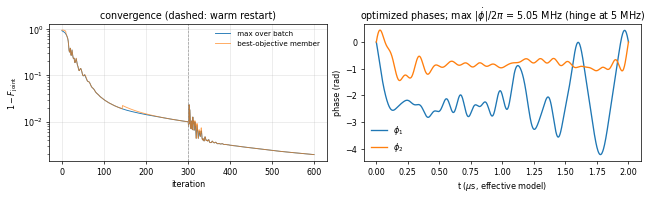

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
rp.plot_convergence(sol['history'], ax[0])
if P['warm_iters']:
    ax[0].axvline(P['iters'], c='0.6', lw=.8, ls='--')
ax[0].set_title('convergence (dashed: warm restart)')
tt = np.linspace(0, sol['T'], 1001); Bc, Bs, dBc, dBs = rp.fourier_basis(sol['T'], 1001, sol['n_harmonics'])
c = sol['coeffs']
for j in (1, 2):
    ax[1].plot(tt*1e6, Bc@c[f'C{j}'] + Bs@c[f'S{j}'], label=r'$\phi_%d$' % j)
ax[1].set_xlabel(r't ($\mu$s, effective model)'); ax[1].set_ylabel('phase (rad)'); ax[1].legend(frameon=False)
ax[1].set_title(r'optimized phases; max $|\dot\phi|/2\pi$ = %.2f MHz (hinge at 5 MHz)' % sol['phidot_max_MHz'])
plt.show()

**Against the shipped effective-model solution.** The shipped coefficients are evaluated with the same propagator. They should reproduce their stored `best_fidelity`.

In [5]:
if have_shipped:
    ref = rp.load_effH_source(P['source'], batch_index=P['source_batch'], target=target)
    print('%-38s %9s %9s %9s %12s' % ('', 'F_joint', 'p_herald', 'F_cav', 'max|phidot|'))
    for name, s in (('this run', sol), ('shipped source %s [%d]' % (P['source'], P['source_batch']), ref)):
        print('%-38s %9.5f %9.5f %9.5f %8.2f MHz' % (name, s['F_joint'], s['p_herald'], s['F_cav'],
                                                     rp.phase_derivative_max_MHz(s['coeffs'], s['T'])))
    print('stored best_fidelity of the shipped source: %.5f' % ref['best_fidelity'])
else:
    print('shipped folders not found; skipping the comparison')

                                         F_joint  p_herald     F_cav  max|phidot|
this run                                 0.99806   0.99808   0.99998     5.05 MHz
shipped source cat15_charfunc_a17 [0]    0.99806   0.99809   0.99998     5.05 MHz
stored best_fidelity of the shipped source: 0.99806


## 2. Ship to hardware

**Rescaling.** $H_{\rm eff}$ depends on time only through $g_{\rm eff}t \propto \alpha\chi t$. The same coefficients therefore give the same state at $(\alpha_{\rm opt}, T)$ and at $(\alpha_{\rm opt}T/T_{\rm oc},\,T_{\rm oc})$: $\alpha_{\rm hw}=\alpha_{\rm opt}T/T_{\rm oc}$, with the Fourier coefficients unchanged.

**Schedule:** sideband ramp $t_{\rm sb}$ | π/2 | Rabi ramp $t_{\rm rr}$ | pre $t_{\rm pre}$ | OC window $T_{\rm oc}$ | ramp-down $t_{\rm dn}$ | π/2, with sin² ramps. With the phases at rest, $\beta(t)=-2i\alpha\sin\Omega_Rt$ vanishes every $h=\pi/\Omega_R=83.33$ ns. Each segment is a whole number of beat intervals rounded to the 4 ns OPX grid (84, 168, 248, 332, 416, 500 ns). $T_{\rm oc}$ is a multiple of $6h=500$ ns, the shortest exact common multiple of $h$ and the 4 ns grid.

**Files**, in the format of every shipped folder:

| file | content | read by |
|---|---|---|
| `final_coeffs.npy` | C1, S1, C2, S2 as float32 (1, N_h) | `make_two_sideband_amp_oc`, `make_rabi_oc_amp` |
| `final_optimizer.npy` | α_hw, T_oc, N_h, χ, Ω_R, Bcos/Bsin on the 1 ns grid | same |
| `hardware_params.npy` | schedule, Stark feed-forward numbers, F_sim, p_g_sim, parity, closing sign | `oc_cell_from_params.py` |
| `controls_data.npy` | φ₁, φ₂, φ̇₁, φ̇₂ on the 1 ns grid (simulation pairing) | plots, checks |
| `target_data.npy`, `final_history.npy` | target state, optimizer history | analysis |
| `gkp_measurement_plan.npy` (GKP only) | the 32 estimator points and weights | `gkp_measurement_hw.py` |

As in the shipped conversion, `hardware_params` is completed in a second step: the displaced-frame simulation of §3 supplies `F_sim`, `p_g_sim` and `frame_deg_sim`.

In [6]:
T_OC, SCHED = P['T_oc_ns'], tuple(P['sched'])
HW = OUT/f"{P['tag']}_Rabi6_chi18_full_a{P['alpha_opt']:g}_T{T_OC}"
rp.check_schedule(SCHED, T_OC)
info = rp.export_hardware(sol, HW, T_OC, SCHED, Nc_sim=P['Nc_sim'], plan=plan)

def note_for(sched):
    return ('%s from rabi_sideband_pipeline.ipynb: %s objective at alpha_opt=%g, T=2 us, %d it; eff-H '
            'F_joint=%.4f, F_cav=%.5f. chi=18.2 kHz, f_Rabi=-6 MHz, beat-aligned schedule %s, '
            'parity %s. Displaced-frame sim Nc=%d, 0.25 ns grid, closed system, time-dependent Stark '
            'feed-forward. T_oc=%d ns.' % (target['name'], P['objective'], P['alpha_opt'],
            len(sol['history']['loss']), sol['F_joint'], sol['F_cav'], sched, target['parity'],
            P['Nc_sim'], T_OC))

R0 = rp.simulate(rp.build_sequence(HW), P['Nc_sim'])        # sec. 3: time-dependent Stark, closing as played
hw = rp.finalize_hardware(HW, SCHED, R0['F'], R0['p_g'], P['Nc_sim'], note=note_for(SCHED),
                          frame_deg=R0['frame_deg'])

schedule  sb 332 | pi2 84 | rabi 168 | pre 0 | OC 5000 | down 332 | pi2 84   (total 6.000 us)
  boundary times (ns): 0 332 416 584 584 5584 5916
  offset from nearest beat null k*h (ns): +0.0 -1.3 -0.7 +0.7 +0.7 +0.7 -0.7
wrote output/rabi_sideband_pipeline/cat15_Rabi6_chi18_full_a17_T5000: alpha_hw = 6.8000 (alpha_opt 17 x 2.00 us / 5.00 us), peak |V| = 0.220 V, peak <n> = 185, max |phidot| = 2.02 MHz, parity even


wrote output/rabi_sideband_pipeline/cat15_Rabi6_chi18_full_a17_T5000/hardware_params.npy: F_sim 0.9993  p_g_sim 0.9768  delta_mean_OC -0.842 MHz  delta_pi2 -0.835 MHz


**What the hardware side sees.** The QUA cell's generators (`make_two_sideband_amp_oc.py`, `make_rabi_oc_amp.py`) are run unchanged on the new folder. The 453/454 MHz/V conversions stand in for `a_memory_m2_rs/bs`, and the Rabi amplitude is left at 1.

In [7]:
HW_SCRIPTS = ('make_two_sideband_amp_oc.py', 'make_rabi_oc_amp.py', 'oc_cell_from_params.py')
if all((rp.ROOT/f).exists() for f in HW_SCRIPTS):
    need = rp.keys_read_by('oc_cell_from_params.py')
    sb, rb, winfo, _ = rp.hardware_waveforms(str(HW))
    print('hardware_params keys read by oc_cell_from_params.py:', len(need), '| missing:',
          [k for k in need if k not in hw] or 'none')
    print('two_sidebands_hold: %d ns (mod 4 = %d), expected %d | peak |V| = %.3f V, mean |V| = %.3f V'
          % (len(sb), len(sb) % 4, hw['sideband_wf_len_ns'], np.abs(sb).max(), np.abs(sb).mean()))
    print('rabi_oc:            %d ns (mod 4 = %d), expected %d | starts at %d ns | Stark phase theta(end) = %.1f rad'
          % (len(rb), len(rb) % 4, hw['rabi_oc_wf_len_ns'], winfo['starts_at_ns'], winfo['theta_total_rad']))
    print('constant-detuning numbers: delta_pi2 = %.3f MHz, delta_mean = %.3f MHz, delta_mean_OC = %.3f MHz'
          % (hw['delta_pi2_Hz']/1e6, hw['delta_mean_Hz']/1e6, hw['delta_mean_OC_Hz']/1e6))
else:
    print('hardware-side scripts not found; skipping the format check')

hardware_params keys read by oc_cell_from_params.py: 12 | missing: none
two_sidebands_hold: 5916 ns (mod 4 = 0), expected 5916 | peak |V| = 0.220 V, mean |V| = 0.110 V
rabi_oc:            5500 ns (mod 4 = 0), expected 5500 | starts at 416 ns | Stark phase theta(end) = -28.0 rad
constant-detuning numbers: delta_pi2 = -0.835 MHz, delta_mean = -0.810 MHz, delta_mean_OC = -0.842 MHz


## 3. Displaced-frame simulation of the full sequence

The played drive $\varepsilon(t)$ is integrated exactly, $\beta(t)=-i\int_0^t\varepsilon\,dt'$ from vacuum. The whole sequence is then propagated in the frame displaced by that $\beta$ (thesis App. A.2):

$$\frac{H'}{\hbar}=\frac{\chi}{2}\sigma_z\left(a^\dagger a+\beta^*a+\beta a^\dagger+|\beta|^2\right)+\frac{\Omega_R}{2}r(t)\,\sigma_x+f(t)\,\sigma_z+H_{\pi/2}(t).$$

Removing the large classical field means $N_c = 40$–$50$ levels suffice, instead of the 340–1000 of the lab-frame check. A full sequence takes about 0.2 s, so the timing search is cheap. The final state is displaced back by $\beta_{\rm end}$. $F$ is the post-selected cavity fidelity, maximized over a phase-space rotation (stored as `frame_deg_sim`).

**Stark compensation $f(t)$** (the $\sigma_z$ coefficient):
- *time-dependent*: $f=-\tfrac{\chi}{2}|\beta_{\rm design}(t)|^2$. This is the design intent (`ff_mode='timedep'`), carried in the phase of the `rabi_oc` waveform.
- *constant*: segment averages over the opening π/2 and over the rest of the sequence (`delta_pi2_Hz`, `delta_mean_Hz`).

Scale 1 applies the full correction. Scale 0.5 is the correction actually applied when the file's $\sigma_z$ number is played as a drive-frequency detuning, which was the initial hardware convention (direct Ramsey shifts were about twice the applied correction; thesis Ch. 7–10). The closing π/2 is either the played pulse (finite, nominal axis) or the instantaneous rotation that maximizes $p_gF$, as calibrated on hardware.

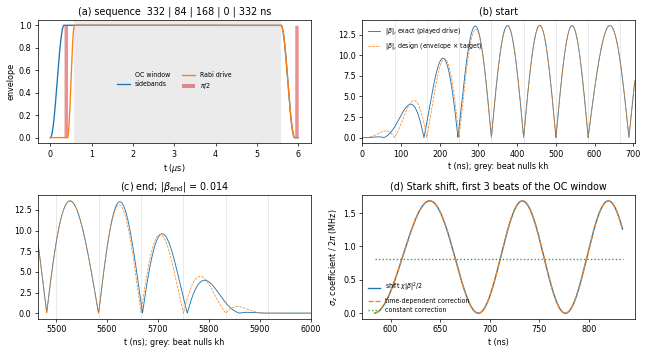

In [8]:
S = rp.build_sequence(HW)
t, ix, h = S['tg']*1e9, S['idx'], rp.beat_ns()
fig, ax = plt.subplots(2, 2, figsize=(10, 5.4), constrained_layout=True)
a = ax[0, 0]
a.axvspan(t[ix['oc'][0]]/1e3, t[ix['oc'][1]]/1e3, color='0.92', lw=0, label='OC window')
a.plot(t/1e3, S['esb'], label='sidebands'); a.plot(t/1e3, S['er'], label='Rabi drive')
a.fill_between(t/1e3, 0, ((S['p2o'] + S['p2c']) > 0).astype(float), color='C3', alpha=.5, lw=0, label=r'$\pi/2$')
a.set_xlabel(r't ($\mu$s)'); a.set_ylabel('envelope'); a.legend(fontsize=7, frameon=False, ncol=2, loc='center')
a.set_title('(a) sequence  ' + ' | '.join(map(str, S['sched'])) + ' ns')
for a, (lo, hi), ttl in ((ax[0, 1], (0, t[ix['oc'][0]] + 120), '(b) start'),
                         (ax[1, 0], (t[ix['down']] - 120, t[-1]), r'(c) end; $|\beta_{\rm end}|$ = %.3f' % abs(S['beta'][ix['end']]))):
    m = (t >= lo) & (t <= hi)
    for k in range(int(lo//h), int(hi//h) + 2):
        a.axvline(k*h, c='0.85', lw=.6, zorder=0)
    a.plot(t[m], np.abs(S['beta'][m]), lw=1, label=r'$|\beta|$, exact (played drive)')
    a.plot(t[m], np.abs(S['bdes'][m]), '--', lw=.8, label=r'$|\beta|$, design (envelope × target)')
    a.set_xlim(lo, hi); a.set_xlabel('t (ns); grey: beat nulls kh'); a.set_title(ttl)
ax[0, 1].legend(fontsize=7, frameon=False)
a = ax[1, 1]; m = (t >= t[ix['oc'][0]]) & (t <= t[ix['oc'][0]] + 3*h)
MHz = 2*np.pi*1e6
a.plot(t[m], S['chi']/2*np.abs(S['beta'][m])**2/MHz, label=r'shift $\chi|\beta|^2/2$')
a.plot(t[m], -rp.stark_ff(S, 'td')[m]/MHz, '--', label='time-dependent correction')
a.plot(t[m], -rp.stark_ff(S, 'const')[m]/MHz, ':', lw=1.5, label='constant correction')
a.set_xlabel('t (ns)'); a.set_ylabel(r'$\sigma_z$ coefficient / 2$\pi$ (MHz)')
a.set_title('(d) Stark shift, first 3 beats of the OC window'); a.legend(fontsize=7, frameon=False)
plt.show()

**Time-dependent against constant Stark compensation** on the schedule above:

In [9]:
print('%-16s %-7s | %7s %7s %7s | %6s %8s' % ('correction', 'closing', 'F', 'p_g', 'p_g*F', 'frame', '|b_end|'))
stark_table = {}
for mode, scale in (('td', 1.0), ('const', 1.0), ('td', 0.5), ('const', 0.5)):
    for closing in ('pulse', 'best'):
        R = rp.simulate(S, P['Nc_sim'], mode, scale, closing)
        stark_table[mode, scale, closing] = R
        name = ('time-dep.' if mode == 'td' else 'constant') + ' x%.1f' % scale
        print('%-16s %-7s | %7.4f %7.4f %7.4f | %6.1f %8.3f' % (
            name, 'played' if closing == 'pulse' else 'best', R['F'], R['p_g'], R['F_joint'], R['frame_deg'], R['beta_end']))

correction       closing |       F     p_g   p_g*F |  frame  |b_end|


time-dep. x1.0   played  |  0.9993  0.9768  0.9761 |   91.0    0.014


time-dep. x1.0   best    |  0.9993  0.9771  0.9764 |   91.0    0.014


constant x1.0    played  |  0.9091  0.5789  0.5263 |   80.5    0.014


constant x1.0    best    |  0.9554  0.9534  0.9108 |   82.0    0.014


time-dep. x0.5   played  |  0.8407  0.8887  0.7472 |  102.0    0.014


time-dep. x0.5   best    |  0.8546  0.8883  0.7591 |  102.0    0.014


constant x0.5    played  |  0.8811  0.7671  0.6759 |   96.0    0.014


constant x0.5    best    |  0.8272  0.9503  0.7861 |   96.0    0.014


**Integer-time search.** Every segment is a whole number of beats, $k\,h$ rounded to the 4 ns grid, with π/2 = 84 ns. The ramp and pre lengths are searched jointly in the full-sequence simulation, once for each compensation. The time-dependent search ranks by post-selected $F$ with the closing pulse as played, the criterion of the shipped conversion. `SEARCH_KEY = 'F_joint'` ranks by $p_gF$ instead, which favors herald probability; for the default cat it prefers $t_{\rm pre}=500$ ns, with $p_g$ 0.993 but $F$ 0.986 and a 0.4 µs longer sequence. The constant-compensation search re-optimizes the closing rotation for each schedule (coarse 19 × 36 scan) and ranks by $p_gF$. The searched time-dependent schedule replaces the preset in `hardware_params` only if it gains more than `MIN_GAIN`.

In [10]:
GRID = dict(k_sb=(3, 4, 5), k_rr=(1, 2), k_pre=(0, 6), k_dn=(2, 3, 4, 5))
print('candidate lengths (ns):', {k: [rp.beat_aligned(x) for x in v] for k, v in GRID.items()}, '\n')
SEARCH_KEY, MIN_GAIN = 'F', 1e-3
best_td, rows_td = rp.schedule_search(HW, P['Nc_sim'], **GRID, stark='td', closing='pulse', key=SEARCH_KEY)
print()
best_c, rows_c = rp.schedule_search(HW, P['Nc_sim'], **GRID, stark='const', closing='best', key='F_joint')

gain = best_td[SEARCH_KEY] - R0[SEARCH_KEY]                  # R0: the preset schedule, sec. 2
print('\nbest searched %s = %.4f vs preset %s: %.4f' % (SEARCH_KEY, best_td[SEARCH_KEY], SCHED, R0[SEARCH_KEY]))
if best_td['sched'] != SCHED and gain > MIN_GAIN:
    print('searched schedule %s replaces the preset' % (best_td['sched'],))
    SCHED = best_td['sched']
    rp.export_hardware(sol, HW, T_OC, SCHED, Nc_sim=P['Nc_sim'], plan=plan, verbose=False)
R = rp.simulate(rp.build_sequence(HW, SCHED), P['Nc_sim'])
hw = rp.finalize_hardware(HW, SCHED, R['F'], R['p_g'], P['Nc_sim'], note=note_for(SCHED), frame_deg=R['frame_deg'])
rp.check_schedule(SCHED, T_OC);

candidate lengths (ns): {'k_sb': [248, 332, 416], 'k_rr': [84, 168], 'k_pre': [0, 500], 'k_dn': [168, 248, 332, 416]} 



48 schedules in 16 s (Nc=40, Stark td x1, closing pulse), sorted by F:
   t_sb   pi2  t_rr t_pre  t_dn |       F     p_g   p_g*F  |b_end|   total
    332    84   168     0   332 |  0.9993  0.9768  0.9761    0.014   6.000
    248    84   168     0   416 |  0.9992  0.9690  0.9682    0.021   6.000
    332    84    84     0   332 |  0.9989  0.9740  0.9728    0.037   5.916
    332    84   168     0   416 |  0.9986  0.9714  0.9701    0.021   6.084
    416    84    84     0   332 |  0.9983  0.9741  0.9725    0.044   6.000
    248    84   168     0   248 |  0.9980  0.9779  0.9759    0.037   5.832
    248    84    84     0   332 |  0.9978  0.9727  0.9706    0.056   5.832
    416    84   168     0   416 |  0.9977  0.9722  0.9700    0.037   6.168



48 schedules in 26 s (Nc=40, Stark const x1, closing best), sorted by F_joint:
   t_sb   pi2  t_rr t_pre  t_dn |       F     p_g   p_g*F  |b_end|   total
    248    84   168     0   168 |  0.9550  0.9718  0.9280    0.084   5.752
    248    84    84     0   168 |  0.9585  0.9674  0.9273    0.102   5.668
    248    84   168     0   248 |  0.9584  0.9603  0.9204    0.037   5.832
    332    84   168     0   248 |  0.9559  0.9603  0.9179    0.079   5.916
    416    84    84     0   248 |  0.9552  0.9598  0.9168    0.110   5.916
    416    84   168     0   248 |  0.9546  0.9602  0.9165    0.095   6.000
    416    84    84     0   332 |  0.9586  0.9535  0.9140    0.044   6.000
    332    84    84     0   248 |  0.9528  0.9590  0.9137    0.125   5.832

best searched F = 0.9993 vs preset (332, 84, 168, 0, 332): 0.9993


wrote output/rabi_sideband_pipeline/cat15_Rabi6_chi18_full_a17_T5000/hardware_params.npy: F_sim 0.9993  p_g_sim 0.9768  delta_mean_OC -0.842 MHz  delta_pi2 -0.835 MHz
schedule  sb 332 | pi2 84 | rabi 168 | pre 0 | OC 5000 | down 332 | pi2 84   (total 6.000 us)
  boundary times (ns): 0 332 416 584 584 5584 5916
  offset from nearest beat null k*h (ns): +0.0 -1.3 -0.7 +0.7 +0.7 +0.7 -0.7


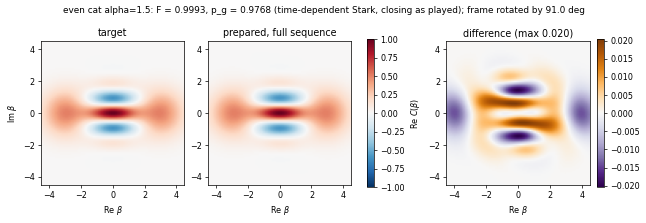

In [11]:
# prepared cavity state (post-selected, rotated back by the frame angle) against the target
v = R['state']*np.exp(-1j*np.radians(R['frame_full_deg'])*np.arange(len(R['state'])))
tb = np.zeros(len(v), complex); tb[:min(len(v), 50)] = target['cav'][:min(len(v), 50)]; tb /= np.linalg.norm(tb)
xs = np.linspace(-4.5, 4.5, 91) if target['kind'] != 'gkp' else np.linspace(-6, 6, 97)
rp.plot_charfunc_pair(v, tb, xs, titles=('target', 'prepared, full sequence'),
                      fig_title='%s: F = %.4f, p_g = %.4f (time-dependent Stark, closing as played); '
                                'frame rotated by %.1f deg' % (target['name'], R['F'], R['p_g'], R['frame_deg']))
plt.show()

## 4. Reproduction check

The shipped effective-model source is run through the same export and simulation, using the shipped schedule. The result is compared file by file with the shipped folder. `F_sim` and `p_g_sim` in the shipped folders come from the lab-frame simulation at $N_c$ = 340–1000; here they are recomputed in the displaced frame.

In [12]:
if have_shipped:
    ref = rp.load_effH_source(P['source'], batch_index=P['source_batch'], target=target)
    hw_ship = np.load(f"{P['shipped']}/hardware_params.npy", allow_pickle=True).item()
    sched0 = tuple(int(hw_ship[k]) for k in rp.SCHED_KEYS)
    REPRO = OUT/(P['shipped'] + '_repro')
    rp.export_hardware(ref, REPRO, int(hw_ship['T_oc_ns']), sched0, Nc_sim=P['Nc_sim'], plan=plan, verbose=False)
    Rr = rp.simulate(rp.build_sequence(REPRO), P['Nc_sim'])
    rp.finalize_hardware(REPRO, sched0, Rr['F'], Rr['p_g'], P['Nc_sim'], note=hw_ship['note'],
                         frame_deg=Rr['frame_deg'], verbose=False)
    rp.compare_folders(REPRO, P['shipped'])
    print('\n%-40s %8s %8s %8s %9s   %s' % ('full sequence, closed system', 'F', 'p_g', 'frame', 'total us', 'schedule'))
    rows = [('shipped folder (stored; lab frame)', hw_ship['F_sim'], hw_ship['p_g_sim'],
             hw_ship.get('frame_deg_sim', np.nan), sched0, int(hw_ship['T_oc_ns'])),
            ('shipped folder (displaced frame here)', Rr['F'], Rr['p_g'], Rr['frame_deg'], sched0,
             int(hw_ship['T_oc_ns'])),
            ('this run (%s)' % P['tag'], hw['F_sim'], hw['p_g_sim'], hw['frame_deg_sim'], SCHED, T_OC)]
    for name, F_, p_, fr, sc, T_ in rows:
        print('%-40s %8.4f %8.4f %8.1f %9.3f   %s' % (name, F_, p_, fr, (sum(sc) + T_ + sc[1])/1e3, sc))
else:
    print('shipped folders not found; skipping the reproduction check')

max relative difference per file: {'controls_data': '4.4e-16', 'final_coeffs': '0.0e+00', 'final_history': '0.0e+00', 'final_optimizer': '0.0e+00', 'hardware_params': '1.4e-16', 'target_data': '0.0e+00'}
  hardware_params[note]: identical
  hardware_params[F_sim]: new 0.9993 | reference 0.9993
  hardware_params[p_g_sim]: new 0.9768 | reference 0.9768
  hardware_params[frame_deg_sim]: new 91.0 | reference 90.88
  hardware_params[Nc_sim]: new 40 | reference 340

full sequence, closed system                    F      p_g    frame  total us   schedule
shipped folder (stored; lab frame)         0.9993   0.9768     90.9     6.000   (332, 84, 168, 0, 332)
shipped folder (displaced frame here)      0.9993   0.9768     91.0     6.000   (332, 84, 168, 0, 332)
this run (cat15)                           0.9993   0.9768     91.0     6.000   (332, 84, 168, 0, 332)


## 5. Notes

- **Beat convention.** §2–3 use the nominal compiler convention for the beat phase, the same one used for every shipped `F_sim`. On 19–20 October, truncation measurements of the played Fock-2 waveform placed the physical displacement nulls at $(k+\tfrac12)h$ (thesis Sec. 7.2.1). Beat alignment on hardware should be checked against that measurement.
- **Stark scale.** The files' `delta_*` numbers are $\sigma_z$ coefficients. Played as drive detunings, or through the `rabi_oc` phase, they apply half of the intended correction; these are the scale-0.5 rows above. The later measured compensation corrects this (thesis Ch. 8).
- **χ.** All designs use the nominal 18.2 kHz. The cavity Ramsey value is −16.09 kHz. To design for the measured value, pass `chi=2*np.pi*16.09e3` to `EffHOptimizer` and set `DEVICE['chi_Hz']`.
- **Closed system.** Decay is not included. For the cat, $T_1 = T_2 = 24$ µs brought 0.999 down to about 0.90 in earlier trajectory runs (`cat_charfunc_low_alpha.ipynb`).
- **Other window lengths.** Re-ship the same solution with another `T_OC` (a multiple of 500 ns) in §2. `rp.load_effH_source(OUT/'..._effH_a..')` reloads a saved solution.